# Estimating the embodied emissions of buildings in Canada for Shahid's paper
Here I use RASMI sampler package to estimate embodied emissions in Canadian buildings:
- importing and querying the raw RASMI kg/m2 data
- linking it to LCA factors from Ecoinvent or any other desired LCA dataset
- performing bootstrapped MC sampling of emissions, based on building share of m2 (assume it remains unchanged)
- Multiply by the emission factors to get a value. Send to Shahid and then adjust for material emissions

## Import and initialize

In [143]:
# import normal package suite
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from rasmi_lca_v1 import *

In [144]:
rlca = RasmiLCA(rasmi_path='', factors_path='')

importing RASMI dataset...
   concrete ...
   brick ...
   wood ...
   steel ...
   glass ...
   plastics ...
   aluminum ...
   copper ...
importing lca factor dataset...
   concrete ...
   brick ...
   wood ...
   steel ...
   glass ...
   plastics ...
   aluminum ...
   copper ...


## Parameters
**Building type split** (assumed constant over time): NRCan Comprehensive Energy Use Database, Residential Sector Canada, Table 24, 2023 values ([link](https://oee.nrcan.gc.ca/corporate/statistics/neud/dpa/showTable.cfm?type=CP&sector=res&juris=ca&year=2023&rn=24)). In the source:
- `RS` (residential single-family) = single detached + single attached + mobile homes
- `RM` (residential multi-family) = apartments

**Structural system** of new construction (`C` concrete, `M` masonry, `S` steel, `T` timber):
- `RS`: single-family housing in Canada is overwhelmingly light wood frame.
- `RM`: StatCan 2021 Census Profile (structural type of dwelling): assumed primarily concrete structures, which some others mxed.

**Demo/replacement rate**: assume a cohort-based MFA flow where x% of stock per year is demolished (https://www.statcan.gc.ca/o1/en/plus/3896-boom-goes-dynamiteand-conversions)

In [170]:
# sampling params
rlca.n = 20000
rlca.seed = 100
geo = 'OECD_CAN'

# NRCan CEUD Residential Canada Table 24, 2023 floor space by building type (million m2)
ceud_floor_2023 = pd.Series({'single_detached': 1456.0, 'single_attached': 289.7, 'apartments': 579.9, 'mobile_homes': 27.5})
type_map = {'single_detached': 'RS', 'single_attached': 'RS', 'mobile_homes': 'RS', 'apartments': 'RM'}
type_shares = ceud_floor_2023.groupby(type_map).sum()
type_shares = type_shares / type_shares.sum()

# structural system mix of new construction for each RASMI function.
struct_weights = {
    'RS': {'C': 0.05, 'M': 0.05, 'S': 0.0, 'T': 0.9},
    'RM': {'C': 0.5, 'M': 0.2, 'S': 0.2, 'T': 0.1},#{'C': 0.25, 'M': 0.25, 'S': 0.25, 'T': 0.25},
}

# truncation error adjustment
btm_up_adj = 1.3

# fraction of previous year's stock demolished and replaced each year
demo_rate = 0.0075

# first year counted in cumulative emissions
cum_start = 2026

type_shares

RM    0.246441
RS    0.753559
dtype: float64

## Floor space
Total residential floor space (million m2) from sheet 2 of `shahid_floorspace.xlsx`

In [171]:
fs = pd.read_excel('data/shahid_casestudy_data/shahid_floorspace.xlsx', sheet_name=1, header=None, nrows=2)
fs = fs.iloc[:, 1:].T.dropna()

floor = pd.Series(fs[1].astype(float).values, index=fs[0].astype(int).values, name='floor_Mm2')
floor.index.name = 'year'
floor.tail()

year
2046    3111.851997
2047    3145.781012
2048    3179.710027
2049    3213.639042
2050    3247.568057
Name: floor_Mm2, dtype: float64

## New floor area
New construction each year = change in stock + demolition replacement:

$S_{new,t} = \max(S_t - S_{t-1}, 0) + r_{demo} F_{t-1}$


In [172]:
d_stock = floor.diff()
print('years with negative stock change (set to 0):', d_stock[d_stock < 0].index.tolist())

new_area = (d_stock.clip(lower=0) + demo_rate * floor.shift(1)).dropna()

# split by RASMI function (million m2/yr)
new_area_type = pd.DataFrame({f: new_area * type_shares[f] for f in ['RS', 'RM']})
assert (new_area_type >= 0).all().all()
new_area_type.tail()

years with negative stock change (set to 0): [2026]


,RS,RM
year,,
2046,42.962997,14.050441
2047,43.154753,14.113152
2048,43.346509,14.175863
2049,43.538266,14.238574
2050,43.730022,14.301286


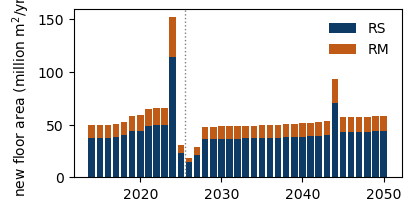

In [173]:
clr = {'total': 'k', 'RS': '#0D3B66', 'RM': '#BF5A17'}

fig, ax = plt.subplots(figsize=(4, 2), constrained_layout=True)
ax.bar(new_area_type.index, new_area_type['RS'], color=clr['RS'], label='RS')
ax.bar(new_area_type.index, new_area_type['RM'], bottom=new_area_type['RS'], color=clr['RM'], label='RM')
ax.axvline(cum_start - 0.5, color='grey', ls=':', lw=1)
ax.set(ylabel='new floor area (million m$^2$/yr)')
ax.legend(frameon=False)

## Sample emission intensities
Sample kgCO2e/m2 for each function and structure with `sample_and_calc`, then build the structure-weighted mixture: each MC draw takes its value from a structure picked with probability `struct_weights`.

In [174]:
structures = ['C', 'M', 'S', 'T']

# kgCO2e/m2 samples for each function and structure, adjust for bottom-up
ef_struct = {f: {s: rlca.sample_and_calc(f, s, geo)*btm_up_adj for s in structures} for f in struct_weights}

# structure-weighted mixture
rng = np.random.default_rng(rlca.seed)
ef = {}
for f, w in struct_weights.items():
    pick = rng.choice(structures, size=rlca.n, p=[w[s] for s in structures])
    ef[f] = np.select([pick == s for s in structures], [ef_struct[f][s] for s in structures])

In [175]:
def pctl(x, axis=None):
    return {'p5': np.percentile(x, 5, axis=axis), 'p50': np.percentile(x, 50, axis=axis),
            'p95': np.percentile(x, 95, axis=axis), 'mean': np.mean(x, axis=axis)}

ef_rows = {(f, s): pctl(ef_struct[f][s]) for f in ef_struct for s in structures}
ef_rows.update({(f, 'mix'): pctl(ef[f]) for f in ef})
ef_summary = pd.DataFrame(ef_rows).T.sort_index()
# bottom_up adjustment
ef_summary.round(1)

p5    p50     p95   mean
RM C    289.4  518.6  1096.5  582.6
   M    201.7  486.2   981.2  527.8
   S    116.5  415.8   764.2  418.2
   T    103.6  267.0   612.4  324.3
   mix  157.7  471.2   987.1  512.4
RS C    196.8  419.2   745.5  438.2
   M    278.2  570.8  1067.9  602.5
   S    193.0  567.2   858.6  548.7
   T    114.7  177.4   404.2  206.5
   mix  115.9  184.8   589.7  238.6

[(0.0, 100.0), Text(0, 0.5, 'percentile')]

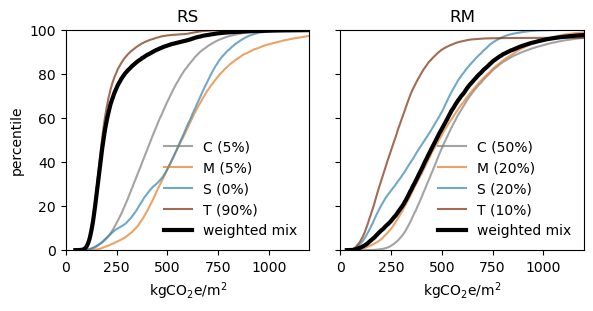

In [176]:
s_clrs = {'C': "#7D7D7D", 'M': '#E27D27', 'S': '#3584B1', 'T': '#7A2E0C'}

fig, ax = plt.subplots(1, 2, figsize=(6, 3), constrained_layout=True, sharey=True)
for a, f in zip(ax, ['RS', 'RM']):
    for s in structures:
        x = np.sort(ef_struct[f][s])
        a.plot(x, np.linspace(0, 100, len(x), endpoint=False), lw=1.5, alpha=0.7, color=s_clrs[s], label=f'{s} ({struct_weights[f][s]:.0%})')
    x = np.sort(ef[f])
    a.plot(x, np.linspace(0, 100, len(x), endpoint=False), lw=3, color='k', label='weighted mix')
    a.set(title=f, xlim=[0, 1200], xlabel='kgCO$_2$e/m$^2$')
    a.legend(frameon=False)
ax[0].set(ylim=[0, 100], ylabel='percentile')

## Embodied emissions
Annual emissions (Mt CO2e) = new floor area x sampled intensity, summed over `RS` and `RM`. The same MC draw is used in every year, so intensity uncertainty is fully correlated over time. Cumulative emissions are summed from `cum_start`.

In [178]:
years = new_area_type.index

# Mt CO2e per year for each draw: Mm2 * 1e6 m2/Mm2 * kgCO2e/m2 / 1e9 kg/Mt
em = {f: np.outer(new_area_type[f].values, ef[f]) * 1e6 / 1e9 for f in ef}
em['total'] = em['RS'] + em['RM']

# cumulative from cum_start
cum_mask = years >= cum_start
em_cum = {k: v[cum_mask].cumsum(axis=0) for k, v in em.items()}

annual = pd.concat({k: pd.DataFrame(pctl(v, axis=1), index=years) for k, v in em.items()}, axis=1)
cumulative = pd.concat({k: pd.DataFrame(pctl(v, axis=1), index=years[cum_mask]) for k, v in em_cum.items()}, axis=1)
annual.round(2)

RS                         RM                       total         \
         p5    p50    p95   mean    p5    p50    p95   mean     p5    p50   
year                                                                        
2014   4.30   6.86  21.88   8.85  1.91   5.72  11.98   6.22   7.94  13.34   
2015   4.36   6.94  22.16   8.97  1.94   5.79  12.13   6.30   8.05  13.52   
2016   4.34   6.92  22.07   8.93  1.93   5.77  12.08   6.27   8.01  13.46   
2017   4.41   7.03  22.43   9.08  1.96   5.86  12.28   6.37   8.14  13.68   
2018   4.62   7.37  23.52   9.51  2.06   6.15  12.87   6.68   8.54  14.34   
2019   5.05   8.05  25.69  10.39  2.25   6.71  14.06   7.30   9.33  15.67   
2020   5.13   8.17  26.09  10.55  2.28   6.82  14.28   7.41   9.47  15.91   
2021   5.64   8.98  28.67  11.60  2.51   7.49  15.70   8.15  10.41  17.49   
2022   5.74   9.14  29.18  11.80  2.55   7.62  15.97   8.29  10.59  17.79   
2023   5.75   9.17  29.27  11.84  2.56   7.65  16.02   8.32  10.62  17.85   
2024  13.27  21.14  67.48  27.30  5.90  17.63  36.94  19.18  24.50  41.16   
2025   2.67   4.25  13.57   5.49  1.19   3.55   7.43   3.86   4.93   8.27   
2026   1.64   2.61   8.33   3.37  0.73   2.18   4.56   2.37   3.02   5.08   
2027   2.48   3.95  12.60   5.10  1.10   3.29   6.90   3.58   4.57   7.69   
2028   4.21   6.71  21.42   8.67  1.87   5.60  11.73   6.09   7.78  13.06   
2029   4.21   6.70  21.39   8.65  1.87   5.59  11.71   6.08   7.77  13.05   
2030   4.21   6.71  21.42   8.67  1.87   5.60  11.73   6.09   7.78  13.07   
2031   4.22   6.73  21.48   8.69  1.88   5.61  11.76   6.11   7.80  13.10   
2032   4.24   6.76  21.59   8.73  1.89   5.64  11.82   6.13   7.84  13.17   
2033   4.27   6.81  21.72   8.79  1.90   5.68  11.89   6.17   7.89  13.25   
2034   4.29   6.84  21.83   8.83  1.91   5.71  11.95   6.20   7.93  13.32   
2035   4.31   6.86  21.90   8.86  1.92   5.72  11.99   6.22   7.95  13.36   
2036   4.33   6.90  22.01   8.90  1.92   5.75  12.05   6.25   7.99  13.42   
2037   4.35   6.94  22.15   8.96  1.94   5.79  12.12   6.29   8.04  13.51   
2038   4.39   7.00  22.33   9.03  1.95   5.84  12.22   6.35   8.11  13.62   
2039   4.43   7.06  22.54   9.12  1.97   5.89  12.34   6.40   8.18  13.74   
2040   4.48   7.13  22.77   9.21  1.99   5.95  12.46   6.47   8.27  13.89   
2041   4.52   7.21  23.01   9.31  2.01   6.01  12.60   6.54   8.35  14.03   
2042   4.58   7.30  23.28   9.42  2.04   6.08  12.75   6.62   8.45  14.20   
2043   4.63   7.38  23.55   9.53  2.06   6.16  12.89   6.69   8.55  14.37   
2044   8.18  13.04  41.62  16.84  3.64  10.88  22.78  11.83  15.11  25.39   
2045   4.96   7.90  25.22  10.20  2.21   6.59  13.81   7.17   9.16  15.38   
2046   4.98   7.94  25.34  10.25  2.22   6.62  13.87   7.20   9.20  15.45   
2047   5.00   7.97  25.45  10.30  2.23   6.65  13.93   7.23   9.24  15.52   
2048   5.03   8.01  25.56  10.34  2.24   6.68  13.99   7.26   9.28  15.59   
2049   5.05   8.04  25.68  10.39  2.25   6.71  14.06   7.30   9.32  15.66   
2050   5.07   8.08  25.79  10.43  2.26   6.74  14.12   7.33   9.36  15.73   

                    
        p95   mean  
year                
2014  28.71  15.07  
2015  29.09  15.26  
2016  28.96  15.20  
2017  29.44  15.45  
2018  30.86  16.20  
2019  33.71  17.69  
2020  34.24  17.97  
2021  37.63  19.75  
2022  38.29  20.09  
2023  38.41  20.16  
2024  88.56  46.48  
2025  17.81   9.34  
2026  10.93   5.74  
2027  16.54   8.68  
2028  28.11  14.75  
2029  28.07  14.73  
2030  28.11  14.75  
2031  28.19  14.80  
2032  28.33  14.87  
2033  28.51  14.96  
2034  28.65  15.04  
2035  28.74  15.08  
2036  28.88  15.16  
2037  29.06  15.25  
2038  29.30  15.38  
2039  29.58  15.52  
2040  29.88  15.68  
2041  30.20  15.85  
2042  30.56  16.04  
2043  30.91  16.22  
2044  54.62  28.67  
2045  33.10  17.37  
2046  33.25  17.45  
2047  33.40  17.53  
2048  33.55  17.61  
2049  33.70  17.68  
2050  33.84  17.76

In [179]:
em['total']

array([[14.20281464, 19.54216965, 15.99869606, ..., 18.2868964 ,
         7.7719127 ,  9.4631483 ],
       [14.3867813 , 19.79529608, 16.20592447, ..., 18.52376349,
         7.87258097,  9.58572287],
       [14.32579802, 19.71138697, 16.13723013, ..., 18.4452442 ,
         7.83921035,  9.54509051],
       ...,
       [16.59289068, 22.83076228, 18.69098637, ..., 21.36424932,
         9.07978461, 11.05562448],
       [16.66629435, 22.93176106, 18.7736716 , ..., 21.45876053,
         9.11995178, 11.10453238],
       [16.73969802, 23.03275984, 18.85635683, ..., 21.55327175,
         9.16011896, 11.15344028]], shape=(37, 20000))

In [180]:
c = cumulative['total'].iloc[-1]
print(f'Cumulative embodied emissions {cum_start}-{years[-1]}: median {c.p50:.0f} Mt CO2e (90% interval {c.p5:.0f}-{c.p95:.0f})')
cumulative.round(1)

Cumulative embodied emissions 2026-2050: median 348 Mt CO2e (90% interval 207-748)


RS                         RM                       total         \
         p5    p50    p95   mean    p5    p50    p95   mean     p5    p50   
year                                                                        
2026    1.6    2.6    8.3    3.4   0.7    2.2    4.6    2.4    3.0    5.1   
2027    4.1    6.6   20.9    8.5   1.8    5.5   11.5    5.9    7.6   12.8   
2028    8.3   13.3   42.4   17.1   3.7   11.1   23.2   12.0   15.4   25.8   
2029   12.5   20.0   63.7   25.8   5.6   16.7   34.9   18.1   23.1   38.9   
2030   16.7   26.7   85.2   34.5   7.4   22.3   46.6   24.2   30.9   51.9   
2031   21.0   33.4  106.7   43.1   9.3   27.9   58.4   30.3   38.7   65.0   
2032   25.2   40.2  128.2   51.9  11.2   33.5   70.2   36.4   46.6   78.2   
2033   29.5   47.0  150.0   60.7  13.1   39.2   82.1   42.6   54.4   91.5   
2034   33.8   53.8  171.8   69.5  15.0   44.9   94.0   48.8   62.4  104.8   
2035   38.1   60.7  193.7   78.4  16.9   50.6  106.0   55.0   70.3  118.1   
2036   42.4   67.6  215.7   87.3  18.9   56.4  118.1   61.3   78.3  131.6   
2037   46.8   74.5  237.8   96.2  20.8   62.2  130.2   67.6   86.3  145.1   
2038   51.2   81.5  260.2  105.3  22.8   68.0  142.4   73.9   94.5  158.7   
2039   55.6   88.6  282.7  114.4  24.7   73.9  154.8   80.3  102.6  172.4   
2040   60.1   95.7  305.5  123.6  26.7   79.8  167.2   86.8  110.9  186.3   
2041   64.6  102.9  328.5  132.9  28.7   85.8  179.8   93.3  119.3  200.3   
2042   69.2  110.2  351.8  142.3  30.8   91.9  192.6  100.0  127.7  214.5   
2043   73.8  117.6  375.3  151.8  32.8   98.1  205.5  106.7  136.3  228.9   
2044   82.0  130.6  416.9  168.7  36.5  109.0  228.2  118.5  151.4  254.3   
2045   86.9  138.5  442.2  178.9  38.7  115.6  242.1  125.6  160.5  269.7   
2046   91.9  146.5  467.5  189.1  40.9  122.2  255.9  132.8  169.7  285.1   
2047   96.9  154.5  493.0  199.4  43.1  128.8  269.9  140.1  179.0  300.7   
2048  101.9  162.5  518.5  209.8  45.4  135.5  283.9  147.3  188.2  316.2   
2049  107.0  170.5  544.2  220.2  47.6  142.2  297.9  154.6  197.6  331.9   
2050  112.1  178.6  570.0  230.6  49.9  149.0  312.0  162.0  206.9  347.6   

                    
        p95   mean  
year                
2026   10.9    5.7  
2027   27.5   14.4  
2028   55.6   29.2  
2029   83.7   43.9  
2030  111.8   58.7  
2031  140.0   73.5  
2032  168.3   88.3  
2033  196.8  103.3  
2034  225.5  118.3  
2035  254.2  133.4  
2036  283.1  148.6  
2037  312.1  163.8  
2038  341.4  179.2  
2039  371.0  194.7  
2040  400.9  210.4  
2041  431.1  226.2  
2042  461.7  242.3  
2043  492.6  258.5  
2044  547.2  287.2  
2045  580.3  304.5  
2046  613.5  322.0  
2047  646.9  339.5  
2048  680.5  357.1  
2049  714.2  374.8  
2050  748.0  392.6

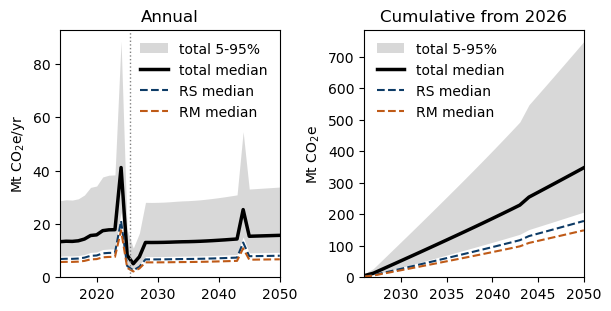

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(6, 3), constrained_layout=True)

for a, df, idx, title, ylab in [(ax[0], annual, years, 'Annual', 'Mt CO$_2$e/yr'),
                                (ax[1], cumulative, years[cum_mask], f'Cumulative from {cum_start}', 'Mt CO$_2$e')]:
    a.fill_between(idx, df['total']['p5'], df['total']['p95'], color='grey', alpha=0.3, lw=0, label='total 5-95%')
    for k in ['total', 'RS', 'RM']:
        a.plot(idx, df[k]['p50'], color=clr[k], lw=2.5 if k == 'total' else 1.5, ls='-' if k == 'total' else '--', label=f'{k} median')
    a.set(title=title, ylabel=ylab, xlim=[idx[0], idx[-1]], ylim=(0, None))
    a.legend(frameon=False)

ax[0].axvline(cum_start - 0.5, color='grey', ls=':', lw=1)

## Sensitivity analysis
How the cumulative total in 2050 (summed from `cum_start`) changes with:
- the **structural system mix** of new construction:
  - discrete scenarios: the base `struct_weights` vs. all new `RS` and `RM` floor area built in a single system (C, M, S or T)
  - a continuous sweep of the **timber share** of new floor area (area-weighted over `RS` and `RM`). Moving above the base shifts non-timber construction to timber, moving below shifts timber to the non-timber systems, which keep their relative base proportions. The base mix sits on this axis.
- the **demolition/replacement rate** (base = `demo_rate`)

Everything else (floor space projection, type split, intensities, `btm_up_adj`) is held at the values above. The same MC draws are reused (including the uniform draws that pick each draw's structure), so differences come only from the parameters being varied.

In [202]:
# sensitivity ranges (edit as needed)
timber_shares = np.linspace(0, 1, 11)  # area-weighted timber share of new floor area
demo_rates = np.linspace(0, 0.015, 7)

# cumulative new floor area from cum_start = growth + demo_rate * prev_stock (million m2)
in_window = d_stock.index >= cum_start
growth = d_stock.clip(lower=0)[in_window].sum()
prev_stock = floor.shift(1)[in_window].sum()

# same uniform draws rng.choice uses to pick structures in the main mixture, so the base case is reproduced
rng = np.random.default_rng(rlca.seed)
u = {f: rng.random(rlca.n) for f in struct_weights}

def mix_ef(f, w):
    """structure-weighted kgCO2e/m2 samples for function f with structural weights w"""
    cdf = np.cumsum([w[s] for s in structures])
    idx = np.minimum(np.searchsorted(cdf / cdf[-1], u[f], side='right'), len(structures) - 1)
    return np.choose(idx, [ef_struct[f][s] for s in structures])

def cum_2050(weights, r):
    """cumulative total Mt CO2e from cum_start to the last year, for each MC draw"""
    ef_tot = sum(type_shares[f] * mix_ef(f, weights[f]) for f in struct_weights)
    return (growth + r * prev_stock) * ef_tot * 1e6 / 1e9

# area-weighted timber share of the base mix
timber_base = sum(type_shares[f] * struct_weights[f]['T'] for f in struct_weights)

def timber_weights(tau):
    """shift the base mix toward (tau > base) or away from (tau < base) timber so the area-weighted
    timber share is tau; non-timber systems keep their relative base proportions"""
    lam = (tau - timber_base) / (1 - timber_base) if tau >= timber_base else (tau - timber_base) / timber_base
    out = {}
    for f, w in struct_weights.items():
        t = w['T'] + lam * (1 - w['T']) if lam >= 0 else w['T'] * (1 + lam)
        other = 1 - w['T']
        out[f] = {s: t if s == 'T' else (w[s] / other * (1 - t) if other > 0 else (1 - t) / 3) for s in structures}
    return out

print(f'base timber share of new floor area: {timber_base:.0%}')
print(f'base check: {np.median(cum_2050(struct_weights, demo_rate)):.1f} vs main result {cumulative["total"]["p50"].iloc[-1]:.1f} Mt CO2e')

base timber share of new floor area: 70%
base check: 347.6 vs main result 347.6 Mt CO2e


,p5,p50,p95,mean
base mix,207.0,348.0,748.0,393.0
all C,340.0,588.0,948.0,608.0
all M,405.0,715.0,1228.0,749.0
all S,304.0,674.0,996.0,663.0
all T,173.0,267.0,626.0,302.0


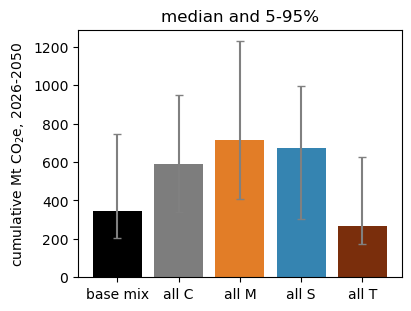

In [203]:
# discrete scenarios: base mix vs. all new construction (RS and RM) in a single structural system
scenarios = {'base mix': struct_weights}
scenarios.update({f'all {s}': {f: {k: float(k == s) for k in structures} for f in struct_weights} for s in structures})
sens_struct = pd.DataFrame({k: pctl(cum_2050(w, demo_rate)) for k, w in scenarios.items()}).T

fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)
x = np.arange(len(sens_struct))
ax.bar(x, sens_struct['p50'], color=['k'] + [s_clrs[s] for s in structures])
ax.errorbar(x, sens_struct['p50'], yerr=[sens_struct['p50'] - sens_struct['p5'], sens_struct['p95'] - sens_struct['p50']],
            fmt='none', ecolor='grey', capsize=3)
ax.set_xticks(x, sens_struct.index)
ax.set(ylabel=f'cumulative Mt CO$_2$e, {cum_start}-{years[-1]}', ylim=(0, None), title='median and 5-95%')
sens_struct.round(0)

<>:17: SyntaxWarning: invalid escape sequence '\s'
<>:17: SyntaxWarning: invalid escape sequence '\s'
C:\Users\keaga\AppData\Local\Temp\ipykernel_41060\3804336189.py:17: SyntaxWarning: invalid escape sequence '\s'
  ax[0].set(ylabel=f'$\sum $Mt CO$_2$e, {cum_start}-{years[-1]}')


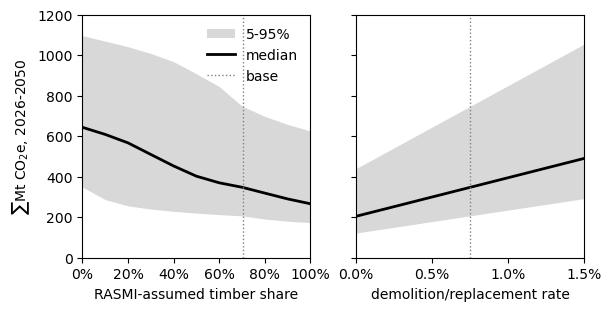

In [210]:
# one-way sensitivities (other parameter held at base)
sens_timber = pd.DataFrame({t: pctl(cum_2050(timber_weights(t), demo_rate)) for t in timber_shares}).T
sens_timber.index.name = 'timber share'
sens_demo = pd.DataFrame({r: pctl(cum_2050(struct_weights, r)) for r in demo_rates}).T
sens_demo.index.name = 'demo rate'

fig, ax = plt.subplots(1, 2, figsize=(6, 3), constrained_layout=True, sharey=True)
for a, df, base, xlab, fmt in [(ax[0], sens_timber, timber_base, 'RASMI-assumed timber share', '{:.0%}'),
                               (ax[1], sens_demo, demo_rate, 'demolition/replacement rate', '{:.1%}')]:
    a.fill_between(df.index, df['p5'], df['p95'], color='grey', alpha=0.3, lw=0, label='5-95%')
    a.plot(df.index, df['p50'], color='k', lw=2, label='median')
    a.axvline(base, color='grey', ls=':', lw=1, label='base')
    a.set(xlabel=xlab, xlim=[df.index[0], df.index[-1]], 
          ylim=(0, 1200)
          )
    a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _, fmt=fmt: fmt.format(v)))
ax[0].set(ylabel=f'$\sum $Mt CO$_2$e, {cum_start}-{years[-1]}')
ax[0].legend(frameon=False)

#pd.concat({'timber share': sens_timber, 'demo rate': sens_demo}).round(0)

In [211]:
sens_timber

,p5,p50,p95,mean
timber share,,,,
0.0,348.925668,644.166132,1096.899062,671.932118
0.1,287.134649,609.098271,1070.125189,632.337391
0.2,256.052055,567.396612,1042.613793,592.779787
0.3,240.325321,510.174643,1009.066588,552.157535
0.4,229.009325,453.314799,968.568888,511.761454
0.5,220.364557,402.792532,908.896199,471.333372
0.6,213.062990,370.176134,846.072955,431.914367
0.7,206.745798,348.152982,749.222321,393.436446
0.8,191.074169,319.306653,698.363279,363.034831


demo rate,0.0000,0.0025,0.0050,0.0075,0.0100,0.0125,0.0150
timber share,,,,,,,
0.0,380.0,468.0,556.0,644.0,732.0,821.0,909.0
0.1,359.0,442.0,526.0,609.0,693.0,776.0,859.0
0.2,334.0,412.0,490.0,567.0,645.0,723.0,801.0
0.3,301.0,370.0,440.0,510.0,580.0,650.0,720.0
0.4,267.0,329.0,391.0,453.0,515.0,577.0,640.0
0.5,237.0,292.0,348.0,403.0,458.0,513.0,568.0
0.6,218.0,269.0,319.0,370.0,421.0,472.0,522.0
0.7,205.0,253.0,300.0,348.0,396.0,444.0,491.0
0.8,188.0,232.0,276.0,319.0,363.0,407.0,450.0


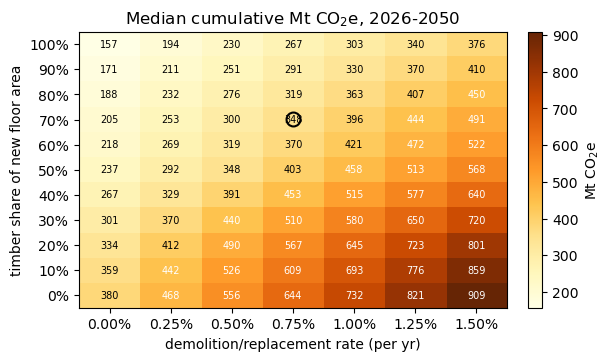

In [205]:
# two-way sensitivity: median cumulative total in 2050 over timber share x demolition rate
grid = pd.DataFrame([[np.median(cum_2050(timber_weights(t), r)) for r in demo_rates] for t in timber_shares],
                    index=pd.Index(timber_shares.round(3), name='timber share'),
                    columns=pd.Index(demo_rates.round(4), name='demo rate'))

fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
im = ax.imshow(grid.values, origin='lower', aspect='auto', cmap='YlOrBr')
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7,
                color='w' if v > grid.values.mean() else 'k')

# base case
ax.plot(np.interp(demo_rate, demo_rates, np.arange(len(demo_rates))),
        np.interp(timber_base, timber_shares, np.arange(len(timber_shares))),
        marker='o', mfc='none', mec='k', ms=10, mew=1.5)

ax.set_xticks(range(len(demo_rates)), [f'{r:.2%}' for r in demo_rates])
ax.set_yticks(range(len(timber_shares)), [f'{t:.0%}' for t in timber_shares])
ax.set(xlabel='demolition/replacement rate (per yr)', ylabel='timber share of new floor area',
       title=f'Median cumulative Mt CO$_2$e, {cum_start}-{years[-1]}')
fig.colorbar(im, ax=ax, label='Mt CO$_2$e')
grid.round(0)